# Imports

In [1]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb,g,fg
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
from src.algos import *
from scipy.optimize import curve_fit
import plotly.graph_objects as go
from matplotlib import pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
%load_ext autoreload
%autoreload 2

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [3]:
pad_factor = 4
xc = 601*pad_factor
yc = 563*pad_factor


# Bottle Beam 

A bottle beam profile $$ I(r) = r^2 \exp\left(-\frac{r^2}{w^2}\right) $$ created using gaussian Input Amplitude on SLM 


## 2d gerchberg saxton

### Simulated

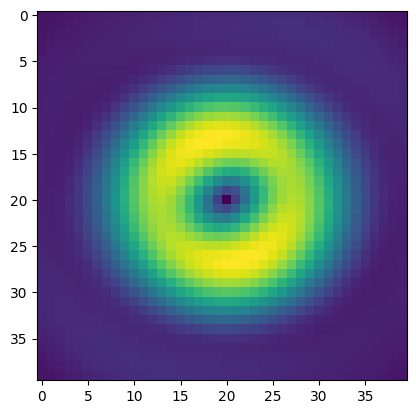

In [30]:
plt.imshow(np.load(f"{figures_path/'raw'/"bb_gs500"}.npy")[yc-20:yc+20,xc-20:xc+20])

### Cam

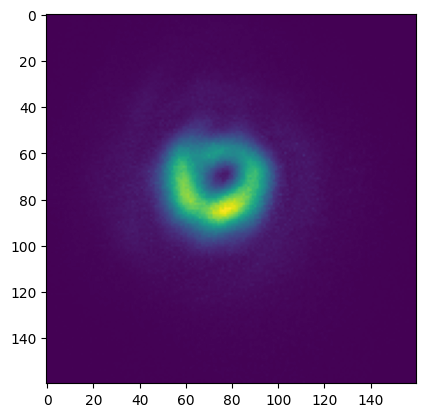

In [31]:
plt.imshow(np.load(f"{figures_path/'raw'/"bb_gs500_cam"}.npy")[230-40*2:230+40*2,1180-40*2:1180+40*2])

## 2d conjugate gradient

### Simulated

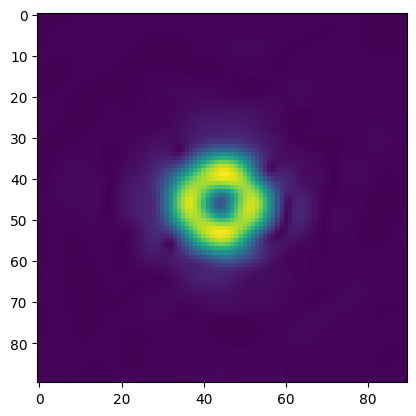

In [35]:
plt.imshow(np.load(f"{figures_path/'raw'/"bb_cg500"}.npy")[670:760,440:530])

### Cam

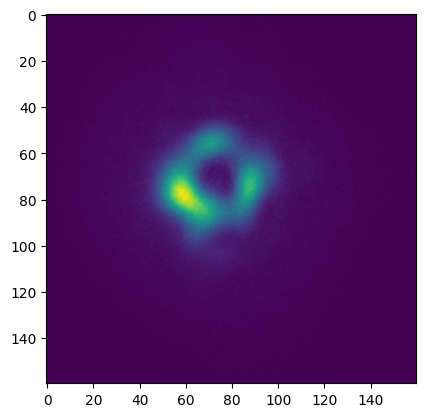

In [36]:
plt.imshow(np.load(f"{figures_path/'raw'/"bb_cg500_cam"}.npy")[230-40*2:230+40*2,1180-40*2:1180+40*2])

# Periodic Bottle Beam

$$
I(r, \theta) = \left( a + b \cos^2(n \theta) \right) \cdot r^2 \exp\left(-\frac{r^2}{w^2} \right)
$$



## 2d gerchberg saxton

### Simulated

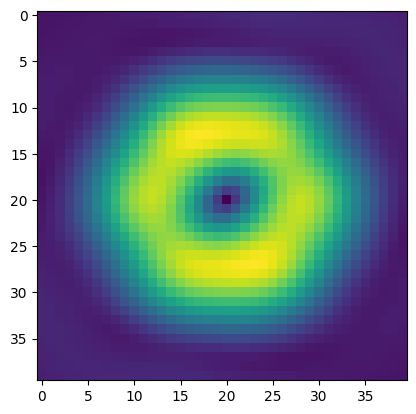

In [37]:
plt.imshow(np.load(f"{figures_path/'raw'/"periodic_bb_gs500"}.npy")[yc-20:yc+20,xc-20:xc+20])

### Cam

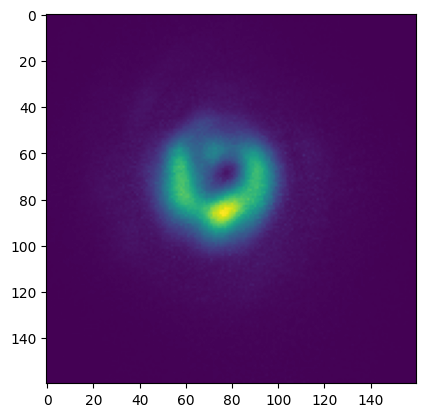

In [27]:
plt.imshow(np.load(f"{figures_path/'raw'/"periodic_bb_gs500_cam"}.npy")[230-40*2:230+40*2,1180-40*2:1180+40*2])

## 2d conjugate gradient

### Simulated

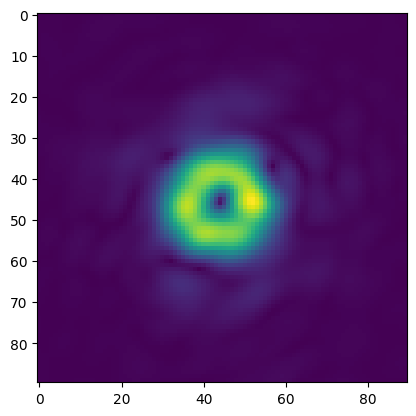

In [24]:
plt.imshow(np.load(f"{figures_path/'raw'/"periodic_bb_cg500"}.npy")[670:760,440:530])

### Cam

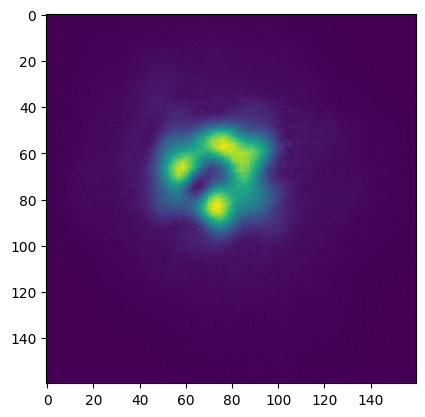

In [26]:
plt.imshow(np.load(f"{figures_path/'raw'/"periodic_bb_cg500_cam"}.npy")[230-40*2:230+40*2,1180-40*2:1180+40*2])

Let 
$$
f(r) = r^{2} e^{-\frac{r^{2}}{w^{2}}} \quad \text{and} \quad g(r) = e^{-\frac{r^{2}}{w^{2}}}.
$$
The deconvolution in the Fourier domain is given by
$$
h(r) = \mathcal{F}_2^{-1}\left[\frac{\mathcal{F}_2[f(r)]}{\mathcal{F}_2[g(r)]}\right].
$$
Using known transforms,
$$
\mathcal{F}_2[g(r)] = \pi w^{2} e^{-\frac{k^{2} w^{2}}{4}}, \quad
\mathcal{F}_2[f(r)] = \pi w^{4} \left( 2 - \frac{k^{2} w^{2}}{2} \right) e^{-\frac{k^{2} w^{2}}{4}},
$$
so that
$$
\frac{\mathcal{F}_2[f(r)]}{\mathcal{F}_2[g(r)]} = w^{2} \left( 2 - \frac{k^{2} w^{2}}{2} \right).
$$
Applying the inverse transform 
$$
\mathcal{F}_2^{-1}[1] = \frac{\delta(r)}{r}, \quad \mathcal{F}_2^{-1}[k^{2}] = -\nabla^{2} \frac{\delta(r)}{r},
$$
we obtain
$$
\boxed{
h(r) = \frac{2 w^{2} \, \delta(r)}{r} + \frac{w^{4}}{2} \nabla^{2} \left( \frac{\delta(r)}{r} \right).
}
$$
This distribution is concentrated at \(r=0\) and represents the deconvolution of the Gaussian blur.
